# A simplified eco audit

*Materials & the Environment, companion notebook to Chapter 6.*

An **eco audit** is a fast, approximate estimate of the **energy** and **CO₂** a product demands over its life, split into five phases:

| Phase | What is counted | Formula used here |
|---|---|---|
| Material | making the materials from ore or feedstock | mass × embodied energy (MJ/kg) |
| Manufacture | the primary shaping process | mass × process energy (MJ/kg) |
| Transport | factory to point of sale | product mass × distance × energy per tonne·km |
| Use | energy the product uses, or the fuel it costs a vehicle to carry it | power × time ÷ conversion efficiency, or added mass × distance × energy per tonne·km |
| Disposal | collecting and processing it at end of life | mass × disposal energy (MJ/kg) |

The method follows the CES EduPack Eco Audit Tool (Ashby, Coulter, Ball and Bream, 2012). Its point is simple: **one phase usually dominates, often with 60% or more of the total**, and that phase is where redesign pays. Because the differences between phases are so large, approximate data are good enough to find it.

The data used here are rounded teaching values, chosen to reproduce the white-paper case studies within about 10%. For real decisions use Granta EduPack or a full LCA database.

In [1]:
import json, os, copy, urllib.request
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

URL = "https://raw.githubusercontent.com/MaterialsandtheEnvironment/MaterialsandtheEnvironment.github.io/main/data/ecoaudit.json"
LOCAL = "../data/ecoaudit.json"
DATA = json.load(open(LOCAL)) if os.path.exists(LOCAL) else json.load(urllib.request.urlopen(URL))
PRODUCTS = {p["id"]: p for p in DATA["products"]}
print(len(DATA["materials"]), "materials,", len(DATA["processes"]), "processes,", len(DATA["transport"]), "transport modes,", len(PRODUCTS), "example products")

31 materials, 8 processes, 8 transport modes, 7 example products


## 1 · The data

Each material has an embodied energy and CO₂ footprint per kilogram for virgin production, the fraction of recycled material in current supply, and the (much lower) values for recycled material. A few rows:

In [2]:
mat = pd.DataFrame(DATA["materials"]).T[["family", "ee", "co2", "rf", "ee_rec"]]
mat.columns = ["family", "MJ/kg (virgin)", "kg CO2/kg", "recycled fraction", "MJ/kg (recycled)"]
mat.loc[["PET", "Polypropylene (PP)", "Low alloy steel", "Cast aluminium alloy", "Copper", "Stainless steel", "Cardboard", "Concrete"]]

,family,MJ/kg (virgin),kg CO2/kg,recycled fraction,MJ/kg (recycled)
PET,Polymers,84,2.3,0.21,36
Polypropylene (PP),Polymers,95,2.7,0.06,40
Low alloy steel,Metals,32,2.3,0.42,9.3
Cast aluminium alloy,Metals,209,12.0,0.55,21.7
Copper,Metals,65,4.2,0.42,14
Stainless steel,Metals,81,5.1,0.36,18
Cardboard,Natural,28,1.1,0.7,18
Concrete,Ceramics & glass,1.2,0.14,0.1,0.8


In [3]:
pd.DataFrame({"Transport (per tonne·km)": {k: f"{v['ee']} MJ, {v['co2']} kg CO2" for k, v in DATA["transport"].items()}})

,Transport (per tonne·km)
Sea freight,"0.13 MJ, 0.01 kg CO2"
River barge,"0.36 MJ, 0.026 kg CO2"
Rail freight,"0.25 MJ, 0.019 kg CO2"
32 tonne truck,"0.46 MJ, 0.033 kg CO2"
24 tonne truck,"0.71 MJ, 0.051 kg CO2"
14 tonne truck,"0.87 MJ, 0.062 kg CO2"
Light goods vehicle,"1.5 MJ, 0.11 kg CO2"
Air freight,"8.3 MJ, 0.59 kg CO2"


## 2 · The model

About 60 lines of Python. Use energy is the only subtle part: a kettle delivers 2 kW of heat, but producing 1 MJ of electricity takes about 3 MJ of primary (fossil) energy, so the delivered energy is divided by an **efficiency factor** (0.33 for electric heating, 0.28 for an electric motor). Products that ride in a vehicle cost fuel in proportion to their mass: about 2 MJ per tonne·km in a family car.

In [4]:
"""A simplified eco audit (energy and CO2 over the life of a product), after the CES EduPack Eco Audit Tool.

    audit(product, data) -> dict with energy (MJ) and CO2 (kg) per life phase, per component, and the end-of-life potential.

A product is a dict: life (years); bom = list of components {name, material, process, mass (kg), eol, recycled};
transport = list of stages {name, type, km}; static = {mode, kW, hours_per_day, days_per_year} or None;
mobile = {mode, km_per_day, days_per_year[, mass_kg]} or None. `recycled` is "virgin", "typical"
(recycle fraction in current supply) or a percentage 0-100.
"""
PHASES = ["Material", "Manufacture", "Transport", "Use", "Disposal"]

def recycled_fraction(comp, mat):
    r = comp.get("recycled", "virgin")
    if r == "virgin": return 0.0
    if r == "typical": return mat["rf"]
    return max(0.0, min(1.0, float(r) / 100))

def audit(product, data):
    M, P, T, S, MO, EOL = (data[k] for k in ["materials", "processes", "transport", "static", "mobile", "eol"])
    life = product["life"]
    E = dict.fromkeys(PHASES, 0.0); C = dict.fromkeys(PHASES, 0.0)
    comps = []
    total_mass = sum(c["mass"] for c in product["bom"])
    eolE = eolC = 0.0
    for c in product["bom"]:
        m = M[c["material"]]; f = recycled_fraction(c, m)
        ee = (1 - f) * m["ee"] + f * m["ee_rec"]; co2 = (1 - f) * m["co2"] + f * m["co2_rec"]
        p = P.get(c.get("process", "None"), P["None"])
        d = EOL.get(c.get("eol", "Landfill"), EOL["None"])
        row = {"name": c["name"], "material": c["material"], "mass": c["mass"], "recycled_%": round(100 * f),
               "Material E": c["mass"] * ee, "Material C": c["mass"] * co2,
               "Manufacture E": c["mass"] * p["ee"], "Manufacture C": c["mass"] * p["co2"],
               "Disposal E": c["mass"] * d["ee"], "Disposal C": c["mass"] * d["co2"]}
        for k in ["Material", "Manufacture", "Disposal"]:
            E[k] += row[k + " E"]; C[k] += row[k + " C"]
        if c.get("eol") == "Recycle":   # credit for the material that recycling can return to the next life
            eolE -= c["mass"] * (m["ee"] - m["ee_rec"]); eolC -= c["mass"] * (m["co2"] - m["co2_rec"])
        comps.append(row)
    for s in product.get("transport") or []:
        t = T[s["type"]]; tkm = total_mass / 1000 * s["km"]
        E["Transport"] += tkm * t["ee"]; C["Transport"] += tkm * t["co2"]
    use = {"static E": 0.0, "static C": 0.0, "mobile E": 0.0, "mobile C": 0.0}
    st = product.get("static")
    if st:
        s = S[st["mode"]]; delivered_MJ = st["kW"] * st["hours_per_day"] * st["days_per_year"] * life * 3.6
        primary = delivered_MJ / s["eff"]
        use["static E"] = primary; use["static C"] = primary * s["co2"]
    mo = product.get("mobile")
    if mo:
        v = MO[mo["mode"]]; mass_t = mo.get("mass_kg", total_mass) / 1000
        tkm = mass_t * mo["km_per_day"] * mo["days_per_year"] * life
        use["mobile E"] = tkm * v["ee"]; use["mobile C"] = tkm * v["co2"]
    E["Use"] = use["static E"] + use["mobile E"]; C["Use"] = use["static C"] + use["mobile C"]
    return {"energy": E, "co2": C, "total_energy": sum(E.values()), "total_co2": sum(C.values()),
            "eol_energy": eolE, "eol_co2": eolC, "components": comps, "use": use, "mass": total_mass}

def dominant(result, key="energy"):
    d = result[key]; tot = sum(d.values()); ph = max(d, key=d.get)
    return ph, d[ph] / tot if tot else 0.0

STRATEGIES = {
    "Material": "Use less material (lighter design), choose materials with lower embodied energy, use recycled content.",
    "Manufacture": "Choose less energy-intensive processes, reduce scrap and process steps.",
    "Transport": "Shorten distances, switch to a more efficient mode (sea, rail, large truck instead of air or small van).",
    "Use": "If it moves: cut mass. If it heats or cools: improve thermal efficiency. If it is electro-mechanical: cut losses.",
    "Disposal": "Design for disassembly and recycling; this phase is rarely dominant.",
}

In [5]:
COLORS = {"Material": "#2a78d6", "Manufacture": "#eb6834", "Transport": "#1baf7a", "Use": "#eda100", "Disposal": "#8a8f8c"}

def show(product, title=None):
    r = audit(product, DATA)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    for ax, key, eol, unit in [(axes[0], "energy", r["eol_energy"], "MJ"), (axes[1], "co2", r["eol_co2"], "kg CO$_2$")]:
        vals = r[key]; names = list(vals)
        ax.bar(names, [vals[n] for n in names], color=[COLORS[n] for n in names])
        if eol:
            ax.bar(["EoL potential"], [eol], color="white", edgecolor="#555", hatch="///")
        ax.axhline(0, color="#555", lw=0.8); ax.set_ylabel(unit); ax.tick_params(axis="x", rotation=30)
        ax.set_title(("Energy" if key == "energy" else "CO$_2$") + f" — total {r['total_' + key]:,.0f} {unit.replace('$_2$', '2').replace('kg CO', 'kg CO')}")
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle(title or product["name"]); fig.tight_layout(); plt.show()
    tab = pd.DataFrame({"Energy (MJ)": r["energy"], "Energy (%)": {k: 100 * v / r["total_energy"] for k, v in r["energy"].items()},
                        "CO2 (kg)": r["co2"], "CO2 (%)": {k: 100 * v / r["total_co2"] for k, v in r["co2"].items()}})
    tab.loc["Total"] = tab.sum()
    ph, share = dominant(r)
    print(f"Dominant phase: {ph} ({share:.0%} of the energy). Strategy: {STRATEGIES[ph]}")
    return tab.round(1)

## 3 · Case study: bottled water

100 one-litre PET bottles (40 g each) with PP caps (1 g), molded and filled in the French Alps, trucked 550 km to London in a 14 t truck, then refrigerated for two days (0.12 kW for 100 bottles). The 100 kg of water travels too, as dead weight.

In [6]:
bottle = PRODUCTS["bottle"]
pd.DataFrame(bottle["bom"])

,name,material,process,mass,eol,recycled
0,Bottles (100),PET,Polymer molding,4.0,Recycle,virgin
1,Caps (100),Polypropylene (PP),Polymer molding,0.1,Landfill,virgin
2,"Water, 100 L (dead weight)",Water (dead weight),None,100.0,None,virgin


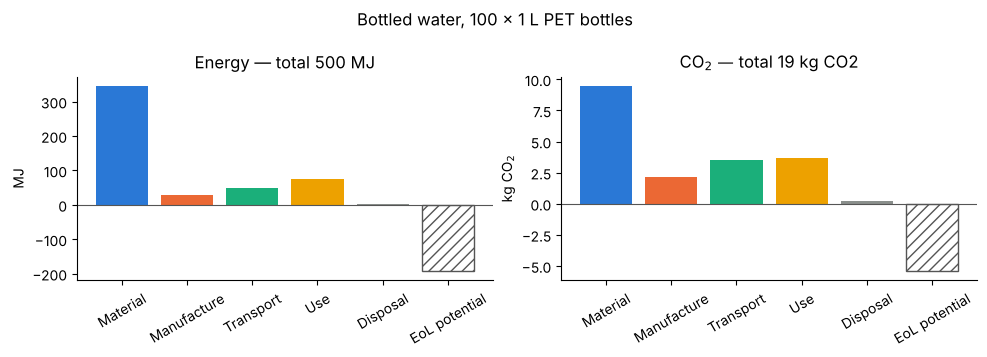

Dominant phase: Material (69% of the energy). Strategy: Use less material (lighter design), choose materials with lower embodied energy, use recycled content.


,Energy (MJ),Energy (%),CO2 (kg),CO2 (%)
Material,345.5,69.1,9.5,49.6
Manufacture,27.9,5.6,2.2,11.4
Transport,49.8,10.0,3.5,18.6
Use,74.1,14.8,3.7,19.4
Disposal,2.8,0.6,0.2,1.0
Total,500.1,100.0,19.1,100.0


In [7]:
show(bottle)

**Check against the white paper (Table 2):** material 344 MJ, manufacture 36 MJ, transport 48 MJ, use 74 MJ. The model gives 346, 28, 50 and 74 MJ. Manufacture is lower because the white paper's own Table 1 gives 6.8 MJ/kg for polymer molding, which yields 28 MJ; its Table 2 and appendix report were produced with other database versions.

The **material** of the bottle dominates. Transporting 100 kg of water 550 km, which feels extravagant, is only about 10% of the energy.

**Exercise (Granta EduPack Exercise 21):** give the PET 35% recycled content. How much does the first-life energy drop?

In [8]:
recycled = copy.deepcopy(bottle)
recycled["bom"][0]["recycled"] = 35
r0, r1 = audit(bottle, DATA), audit(recycled, DATA)
print(f"First-life energy: {r0['total_energy']:.0f} MJ -> {r1['total_energy']:.0f} MJ ({100*(r1['total_energy']/r0['total_energy']-1):+.0f}%)")

First-life energy: 500 MJ -> 433 MJ (-13%)


EduPack reports −11% with its database; this model gives −13%. Differences below 20% are not significant in an eco audit; the conclusion is the same.

### A new example: a reusable steel bottle

One stainless-steel bottle (300 g, PP cap), shipped from Asia, refilled 100 times from the tap and washed each time (1.2 kW for 2.5 minutes). Same service as the 100 PET bottles above.

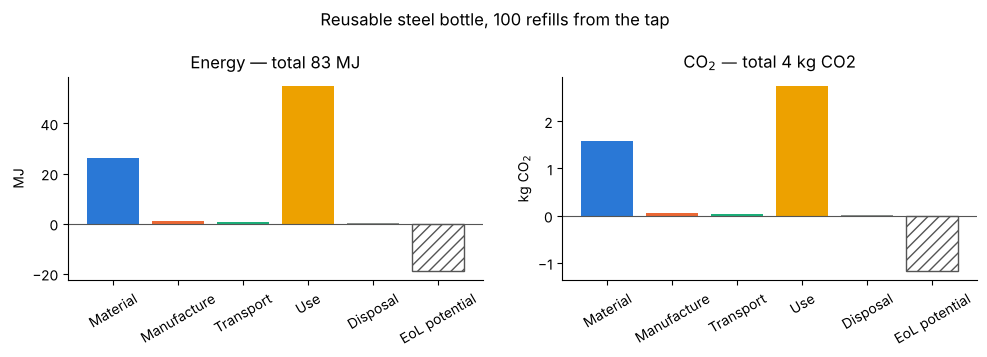

Dominant phase: Use (66% of the energy). Strategy: If it moves: cut mass. If it heats or cools: improve thermal efficiency. If it is electro-mechanical: cut losses.


,Energy (MJ),Energy (%),CO2 (kg),CO2 (%)
Material,26.2,31.7,1.6,35.6
Manufacture,0.9,1.1,0.1,1.5
Transport,0.5,0.6,0.0,0.8
Use,55.0,66.4,2.7,61.7
Disposal,0.2,0.3,0.0,0.3
Total,82.8,100.0,4.5,100.0


In [9]:
reuse = PRODUCTS["reusable"]
show(reuse)

In [10]:
a, b = audit(bottle, DATA), audit(reuse, DATA)
print(f"100 PET bottles: {a['total_energy']:.0f} MJ, {a['total_co2']:.1f} kg CO2")
print(f"1 steel bottle, 100 uses: {b['total_energy']:.0f} MJ, {b['total_co2']:.1f} kg CO2  ->  {a['total_energy']/b['total_energy']:.0f}x less energy")
# how many uses before the steel bottle pays back its material?
per_use_pet = a["total_energy"] / 100
fixed_steel = b["energy"]["Material"] + b["energy"]["Manufacture"] + b["energy"]["Transport"]
per_use_steel = b["energy"]["Use"] / 100
print(f"Break-even after about {fixed_steel / (per_use_pet - per_use_steel):.0f} uses")

100 PET bottles: 500 MJ, 19.1 kg CO2
1 steel bottle, 100 uses: 83 MJ, 4.5 kg CO2  ->  6x less energy
Break-even after about 6 uses


## 4 · Case study: electric kettle

A 2 kW, 1.7 L kettle made in South-East Asia, air-freighted 11 000 km to Europe, then trucked 250 km. It boils 1 L in 3 minutes, three times a day, for three years.

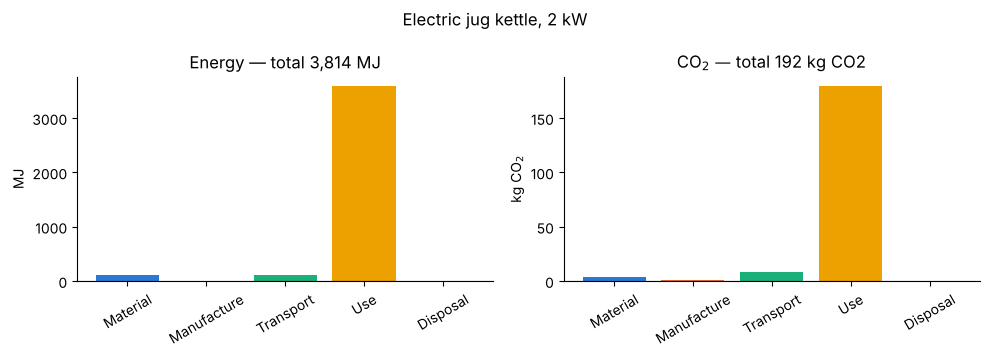

Dominant phase: Use (94% of the energy). Strategy: If it moves: cut mass. If it heats or cools: improve thermal efficiency. If it is electro-mechanical: cut losses.


,Energy (MJ),Energy (%),CO2 (kg),CO2 (%)
Material,107.9,2.8,3.6,1.9
Manufacture,7.0,0.2,0.5,0.3
Transport,115.1,3.0,8.2,4.3
Use,3583.6,94.0,179.2,93.6
Disposal,0.3,0.0,0.0,0.0
Total,3813.9,100.0,191.5,100.0


In [11]:
kettle = PRODUCTS["kettle"]
show(kettle)

White paper (Table 4): material 107 MJ, manufacture 6.9, transport 115, use 3 583 MJ (94%). Use dominates so strongly that only thermal efficiency matters. What about sea freight instead of air?

In [12]:
sea = copy.deepcopy(kettle)
sea["transport"][0] = {"name": "SE Asia to Europe", "type": "Sea freight", "km": 17000}
for p in (kettle, sea):
    r = audit(p, DATA); print(f"{p['transport'][0]['type']:>12}: transport {r['energy']['Transport']:6.1f} MJ = {100*r['energy']['Transport']/r['total_energy']:.1f}% of the life energy")
better = copy.deepcopy(kettle); better["static"]["kW"] *= 0.8   # e.g. a double wall that saves 20% of the heating energy
print(f"A 20% more efficient kettle saves {audit(kettle, DATA)['total_energy'] - audit(better, DATA)['total_energy']:.0f} MJ, "
      f"more than {audit(kettle, DATA)['energy']['Material']:.0f} MJ for all its materials.")

 Air freight: transport  115.1 MJ = 3.0% of the life energy
 Sea freight: transport    3.0 MJ = 0.1% of the life energy
A 20% more efficient kettle saves 717 MJ, more than 108 MJ for all its materials.


## 5 · Case study: family car — material against use

An 1 800 kg car driven 25 000 km a year for 10 years. Only the materials and the fuel are counted.

In [13]:
car = PRODUCTS["car"]
r = audit(car, DATA)
print(f"Material: {r['energy']['Material']/1000:.0f} GJ, use: {r['energy']['Use']/1000:.0f} GJ  "
      f"(white paper: 162 and 884 GJ) -> use is {r['energy']['Use']/r['total_energy']:.0%} of the total")
pd.DataFrame(r["components"]).set_index("name")[["material", "mass", "Material E"]].sort_values("Material E", ascending=False).round(0)

Material: 151 GJ, use: 927 GJ  (white paper: 162 and 884 GJ) -> use is 86% of the total


,material,mass,Material E
name,,,
Aluminium,Cast aluminium alloy,438,91542.0
Steel,Low alloy steel,850,27200.0
Thermosets,Polyester (thermoset),93,7905.0
Thermoplastics (PU),Polyurethane (PU),74,6660.0
Thermoplastics (PVC),PVC,74,4440.0
Elastomers,Butyl rubber,40,4400.0
Textiles,Polyester fibre (textile),47,3995.0
Other metals,Copper,61,3965.0
Glass,Borosilicate glass,40,1000.0


Aluminium is a quarter of the mass and well over half of the material energy.

## 6 · Substitution: steel or aluminium bumper?

A 14 kg steel bumper or a 10 kg aluminium one. Aluminium costs far more energy to make but saves fuel on every kilometre. Where is the break-even?

Virgin material: break-even at 200,000 km
Recycled material: break-even at 91,000 km


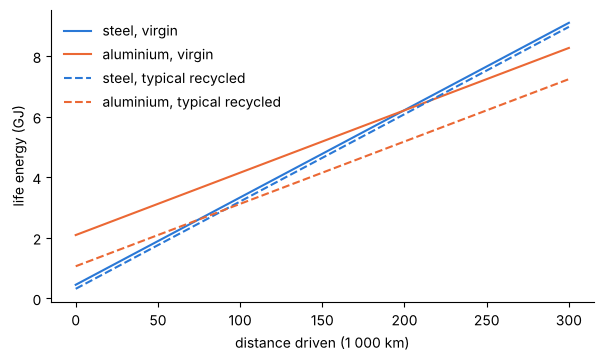

In [14]:
import numpy as np
km = np.linspace(0, 300_000, 301)
fuel = DATA["mobile"]["Family car, gasoline"]["ee"]          # MJ per tonne·km
def life_energy(material, mass, recycled):
    m = DATA["materials"][material]; f = m["rf"] if recycled else 0
    return mass * ((1 - f) * m["ee"] + f * m["ee_rec"]) + mass / 1000 * km * fuel
fig, ax = plt.subplots(figsize=(7, 3.8))
for rec, ls in [(False, "-"), (True, "--")]:
    st, al = life_energy("Low alloy steel", 14, rec), life_energy("Cast aluminium alloy", 10, rec)
    ax.plot(km / 1000, st / 1000, ls, color="#2a78d6", label=f"steel, {'typical recycled' if rec else 'virgin'}")
    ax.plot(km / 1000, al / 1000, ls, color="#eb6834", label=f"aluminium, {'typical recycled' if rec else 'virgin'}")
    i = np.argmax(al < st); print(f"{'Recycled' if rec else 'Virgin'} material: break-even at {km[i]:,.0f} km")
ax.set_xlabel("distance driven (1 000 km)"); ax.set_ylabel("life energy (GJ)"); ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.show()

White paper: about 200 000 km with virgin metal, under 100 000 km with the recycled content in current supply. The model gives about 199 000 and 91 000 km. Recycled aluminium needs a tenth of the energy of primary aluminium, which moves the break-even within an ordinary car's life.

## 7 · Case study: a space heater that rides in a van

A 7 kg LPG heater (9.3 kW) used 2 hours a day, 20 days a year, and carried 420 km a week in a light goods vehicle, for 3 years. It uses energy in two ways: the gas it burns (static mode), and the extra fuel the van burns to carry it (mobile mode).

Static (LPG): 4464 MJ, mobile (being carried): 644 MJ  -> 87% / 13%  (white paper: 87% / 13%)


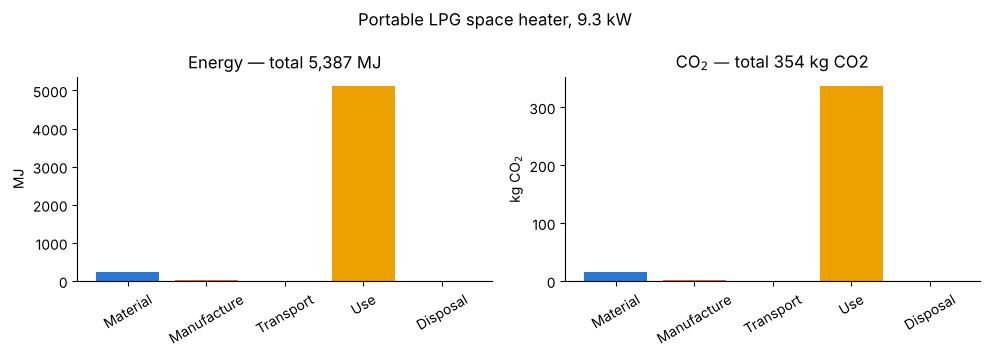

Dominant phase: Use (95% of the energy). Strategy: If it moves: cut mass. If it heats or cools: improve thermal efficiency. If it is electro-mechanical: cut losses.


,Energy (MJ),Energy (%),CO2 (kg),CO2 (%)
Material,246.8,4.6,15.2,4.3
Manufacture,20.3,0.4,1.6,0.4
Transport,11.0,0.2,0.8,0.2
Use,5107.9,94.8,336.2,95.0
Disposal,1.4,0.0,0.1,0.0
Total,5387.3,100.0,353.9,100.0


In [15]:
heater = PRODUCTS["heater"]
r = audit(heater, DATA)
print(f"Static (LPG): {r['use']['static E']:.0f} MJ, mobile (being carried): {r['use']['mobile E']:.0f} MJ  "
      f"-> {r['use']['static E']/r['energy']['Use']:.0%} / {r['use']['mobile E']/r['energy']['Use']:.0%}  (white paper: 87% / 13%)")
show(heater)

## 8 · Audit your own product

Copy this template, fill in the bill of materials and run it. Material, process, transport and use-mode names must match the keys of `DATA` (listed below). As in EduPack, it is enough to enter the components that make up about 95% of the mass, plus a "residual components" row using polycarbonate and polymer molding as a mid-range proxy.

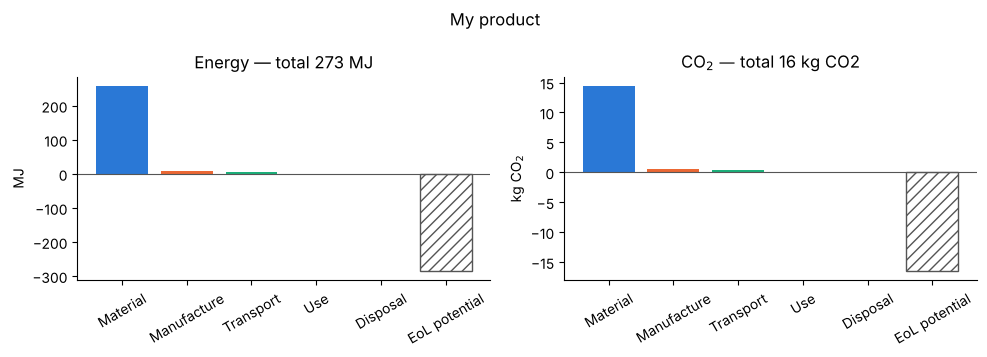

Dominant phase: Material (95% of the energy). Strategy: Use less material (lighter design), choose materials with lower embodied energy, use recycled content.


,Energy (MJ),Energy (%),CO2 (kg),CO2 (%)
Material,258.4,94.6,14.4,92.8
Manufacture,8.1,3.0,0.6,4.0
Transport,5.4,2.0,0.4,2.7
Use,0.0,0.0,0.0,0.0
Disposal,1.2,0.5,0.1,0.6
Total,273.1,100.0,15.6,100.0


In [16]:
mine = {
    "name": "My product", "life": 5,
    "bom": [
        {"name": "Frame", "material": "Wrought aluminium alloy", "process": "Metal deformation (forging, rolling)", "mass": 1.6, "eol": "Recycle", "recycled": "typical"},
        {"name": "Seat and grips", "material": "Polyurethane (PU)", "process": "Polymer molding", "mass": 0.4, "eol": "Landfill", "recycled": "virgin"},
        {"name": "Residual components", "material": "Polycarbonate (PC)", "process": "Polymer molding", "mass": 0.2, "eol": "Landfill", "recycled": "virgin"},
    ],
    "transport": [{"name": "Factory to shop", "type": "Sea freight", "km": 18000}, {"name": "Delivery", "type": "Light goods vehicle", "km": 80}],
    "static": None,
    "mobile": None,
}
show(mine)

In [17]:
print("Materials:", ", ".join(DATA["materials"]))
print("Processes:", ", ".join(DATA["processes"]))
print("Transport:", ", ".join(DATA["transport"]))
print("Static use:", ", ".join(DATA["static"]))
print("Mobile use:", ", ".join(DATA["mobile"]))

Materials: PET, Polypropylene (PP), Polyethylene (PE), PVC, Polycarbonate (PC), Polyurethane (PU), Polyester (thermoset), Phenolic, Rigid polymer foam, Natural rubber (NR), Butyl rubber, Polyester fibre (textile), Low carbon steel, Low alloy steel, Stainless steel, Cast iron, Iron, Cast aluminium alloy, Wrought aluminium alloy, Copper, Brass, Nickel-chromium alloy, Titanium alloy, CFRP, GFRP, Borosilicate glass, Soda-lime glass, Concrete, Cardboard, Softwood, Water (dead weight)
Processes: Polymer molding, Polymer extrusion, Metal casting, Metal deformation (forging, rolling), Machining (light), Glass molding, Construction (assembly, cutting), None
Transport: Sea freight, River barge, Rail freight, 32 tonne truck, 24 tonne truck, 14 tonne truck, Light goods vehicle, Air freight
Static use: Electric to thermal, Electric to mechanical, Electric to light / electronics, Fossil fuel to thermal (enclosed), Fossil fuel to mechanical
Mobile use: Family car, gasoline, Family car, diesel, Light 

## 9 · What to remember

1. One phase usually dominates. Find it first; refine the data only if two phases are close.
2. Products that use energy (kettle, car, heater) are dominated by **use**: the target is efficiency or mass, not the embodied energy of the materials.
3. Products that do not (packaging, furniture, the bottle) are dominated by **material**: use less, use lower-energy materials, use recycled content.
4. Material substitution is a trade-off between phases; compute the break-even rather than guessing.
5. Differences under about 20% are not significant with data of this precision.

**Reference:** M. F. Ashby, P. Coulter, N. Ball, C. Bream, *The CES EduPack Eco Audit Tool — A White Paper*, Granta Design, 2012; M. F. Ashby, *Materials and the Environment: Eco-informed Material Choice*, 2nd ed., Butterworth-Heinemann, 2012.